In [1]:
import torch
import os
import monai.transforms as mt
import monai.data as md
import scipy.io as sio
import numpy as np
from liutuo_utils import compare_3d_jet,compare_3d,donkey_noise_like
import matplotlib.pyplot as plt
import pandas as pd
device_id =2

# 设置 PyTorch 的默认 CUDA 设备
torch.cuda.set_device(device_id)

# 确认当前默认 CUDA 设备
current_device = torch.cuda.current_device()
print(f"Switched to CUDA device: {current_device}")

/home/data/liutuo/.conda/envs/chouchou/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Switched to CUDA device: 2


In [2]:
from transformers import AutoProcessor, AutoModel

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"

processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)




In [3]:
from transformers import AutoProcessor, AutoModel
import torch
# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

# 将模型转移到设备
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()
context_length = 256

# modal_information = [
#     'T1-weighted imaging is an MRI technique that emphasizes tissues with lower water content. In T1-weighted images, bright areas represent fatty tissues, while dark areas indicate tissues with higher water content, such as fluids or edema.',
#     'PET (Positron Emission Tomography) visualizes metabolic processes using FDG (Fluorodeoxyglucose) as the radioactive tracer. Bright areas indicate high glucose uptake, like active brain regions or tumors, while dark areas show lower activity. PET pixel values represent tracer concentration, with higher values indicating greater metabolic activity.',
#     'CT (Computed Tomography) visualizes internal structures using X-rays. Bright areas (high density) represent dense tissues like bone, while dark areas (low density) indicate less dense tissues, such as air or fat. CT density values correlate with tissue composition, while PET density values reflect metabolic activity, with high values indicating increased glucose uptake.'
# ]

modal_information = [
    'T1-weighted MRI highlights tissues with low water content. Bright areas represent fatty tissues like brain white matter or subcutaneous fat. Dark areas indicate high water content tissues such as fluids, edema, or cerebrospinal fluid. This contrast helps to differentiate between various soft tissues based on their water content and composition, useful for detecting lesions or structural abnormalities.',
    
    'PET (Positron Emission Tomography) utilizes FDG (Fluorodeoxyglucose), a radioactive glucose analog, as a tracer to visualize and measure metabolic activity in tissues. Once injected, FDG accumulates in areas with high glucose uptake, which appear bright on PET images. These bright regions indicate areas of increased metabolic activity, such as actively functioning brain regions, tumors, or inflamed tissues. Conversely, areas with low glucose uptake, representing lower metabolic activity, appear darker. By analyzing the concentration of FDG absorbed in different tissues, PET imaging plays a critical role in evaluating tumor activity, brain function, and other metabolic processes. ',
    
    'CT (Computed Tomography) uses X-rays to produce detailed images of internal body structures. Dense tissues like bone appear bright due to high X-ray absorption, while less dense tissues like air or fat appear dark. CT images are crucial for evaluating anatomical structures, diagnosing fractures, tumors, and internal bleeding. Unlike PET, which shows metabolic activity, CT primarily provides structural and density information.'
]
# 使用 tokenizer 进行文本处理
tokenizer = processor.tokenizer
inputs = tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=context_length)
texts = inputs['input_ids'].to(device)

# 计算文本嵌入特征
with torch.no_grad():
    text_features = model.get_text_features(texts)  # Replace `get_text_features` with the correct method
    print(text_features.shape, text_features.dtype)  # 打印嵌入特征的形状和数据类型


torch.Size([3, 512]) torch.float32


In [4]:
import os
import pandas as pd
import torch
from transformers import AutoProcessor, AutoModel
import scipy.io as sio

# 读取CSV文件并创建Subject到Description和Group的映射
label_path1 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI1_imdb_with_meta_description.csv"
label_path2 = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/ADNI2_imdb_with_meta_description.csv"

label1 = pd.read_csv(label_path1)
label2 = pd.read_csv(label_path2)

label1_dict = dict(zip(label1["Subject"], label1["Group"]))
label2_dict = dict(zip(label2["Subject"], label2["Group"]))

label1_desc_dict = dict(zip(label1["Subject"], label1["description"]))
label2_desc_dict = dict(zip(label2["Subject"], label2["description"]))

# 使用本地路径加载处理器和模型
local_model_path = "/home/data/liutuo/code/BiomedCLIP"
processor = AutoProcessor.from_pretrained(local_model_path, trust_remote_code=True)
model = AutoModel.from_pretrained(local_model_path, trust_remote_code=True)

device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.eval()

# 定义函数以读取.mat文件
def mat_load(mat_file_dir):
    mat = sio.loadmat(mat_file_dir)
    image = mat["IMG"]
    return image

# 获取路径中的数据列表
def get_data_list_from_path(path):
    data_list = [os.path.join(path, data) for data in os.listdir(path)]
    return data_list

# 获取路径中的数据并创建映射
def get_data_from_path(path, label_dict):
    data_all = []
    for data in os.listdir(path):
        image = os.path.join(path, data)
        name = data[:-4]
        try:
            label = label_dict[name]
        except KeyError:
            continue
        data_all.append({"image": image, "name": name, "label": label})
    return data_all

# 获取配对数据并附加Description
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for data in os.listdir(path):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
        })
    return data_all

# 设置路径
mri_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI"
pet_path = "/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET"

# 获取MRI数据并创建映射
data_all = get_data_from_path(mri_path, label1_dict)
data_all_adni2 = get_data_from_path(mri_path, label2_dict)

mri_name_image_dict = dict(zip([data["name"] for data in data_all],
                               [data["image"] for data in data_all]))
mri_name_image_dict_adni2 = dict(zip([data["name"] for data in data_all_adni2],
                                     [data["image"] for data in data_all_adni2]))

# 获取配对数据并附加Description
paired_all_with_desc1 = get_data_from_path_paired_with_description(pet_path, label1_dict, label1_desc_dict, mri_name_image_dict)
paired_all_with_desc2 = get_data_from_path_paired_with_description(pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# 将Description转化为BiomedCLIP嵌入
modal_information = [data["description"] for data in paired_all_with_desc]
text_inputs = processor.tokenizer(modal_information, padding=True, truncation=True, return_tensors="pt", max_length=256).to(device)

with torch.no_grad():
    desc_text_features = model.get_text_features(text_inputs['input_ids'])  # 使用实际的特征提取方法
    print(desc_text_features.shape, desc_text_features.dtype)


torch.Size([1129, 512]) torch.float32


In [5]:
print(paired_all_with_desc)

[{'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', 'name': '033_S_1281', 'label': 'AD', 'description': 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.'}, {'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/131_S_0409.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/131_S_0409.mat', 'name': '131_S_0409', 'label': 'MCI', 'descr

In [6]:
c_mri= text_features[0].unsqueeze(0).to(dtype=torch.float32).to(device)
c_pet= text_features[1].unsqueeze(0).to(dtype=torch.float32).to(device)
c_pet= torch.load("/home/data/liutuo/code/checkpoint/c_pet_optimized.pt").to(device) # 1 x 512
c_ct= text_features[2].unsqueeze(0).to(dtype=torch.float32).to(device)
print(c_pet.shape)

You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


torch.Size([1, 512])


In [7]:
# 修改后的函数，用于获取配对数据并附加Description和text_mri, text_pet
def get_data_from_path_paired_with_description(path, label_dict, label_desc_dict, mri_name_image_dict):
    data_all = []
    for i, data in enumerate(os.listdir(path)):
        pet = os.path.join(path, data)
        name = data[:-4]
        try:
            mri = mri_name_image_dict[name]
            label = label_dict[name]
            description = label_desc_dict[name]
        except KeyError:
            continue
        data_all.append({
            "pet": pet,
            "mri": mri,
            "name": name,
            "label": label,
            "description": description,
            "mri_index": i,
            "pet_index": i,
        })
    return data_all

# 使用新的函数生成配对数据
paired_all_with_desc1 = get_data_from_path_paired_with_description(
    pet_path, label1_dict, label1_desc_dict, mri_name_image_dict
)
paired_all_with_desc2 = get_data_from_path_paired_with_description(
    pet_path, label2_dict, label2_desc_dict, mri_name_image_dict_adni2
)

# 合并两个数据集
paired_all_with_desc = paired_all_with_desc1 + paired_all_with_desc2

# # 过滤掉label不是CN或AD的样本
# paired_all_with_desc = [data for data in paired_all_with_desc if data["label"] in ["CN", "AD"]]

# 输出检查
print(paired_all_with_desc[0].keys())  # 检查新的key是否成功加入
print(paired_all_with_desc[0].values()) 
print(len(paired_all_with_desc))
for new_index, data in enumerate(paired_all_with_desc):
    data['index'] = new_index


dict_keys(['pet', 'mri', 'name', 'label', 'description', 'mri_index', 'pet_index'])
dict_values(['/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/033_S_1281.mat', '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/033_S_1281.mat', '033_S_1281', 'AD', 'Subject is a 78-year-old female with a weight of 69.9 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 1.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 24.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 5.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 22.0.', 4, 4])
1129


In [8]:
for new_index, data in enumerate(paired_all_with_desc):
    data['mri_index'] = new_index
    data['pet_index'] = new_index

In [9]:
train_data = paired_all_with_desc[:800]

val_data = paired_all_with_desc[800:]

# 输出检查
print(f"训练集大小: {len(train_data)}") 
print(f"验证集大小: {len(val_data)}")   


训练集大小: 800
验证集大小: 329


In [10]:
print(val_data)

[{'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/051_S_5005.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/051_S_5005.mat', 'name': '051_S_5005', 'label': 'AD', 'description': 'Subject is a 78-year-old male with a weight of 65.0 kg. The global Clinical Dementia Rating (CDR) score, which assesses dementia severity (0: no dementia to 3: severe dementia), is 2.0. The Mini-Mental State Examination (MMSE) score, assessing cognitive function (0: severe impairment to 30: normal), is 20.0. The Geriatric Depression Scale (GDS) score, screening depression (0: no depression to 15: severe depression), is 0.0. The Functional Activities Questionnaire (FAQ) score, assessing daily activity impairment (0: no impairment to 30: severe impairment), is 25.0.', 'mri_index': 800, 'pet_index': 800, 'index': 800}, {'pet': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/PET/027_S_2245.mat', 'mri': '/home/data/liutuo/code/liutuo_data/ADNI1+2_baseline/MRI/027_S_2245.ma

In [11]:
def mri_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_mri], dim=0)

def pet_index_transform(x):
    return torch.cat([desc_text_features[x].unsqueeze(0), c_pet], dim=0)

from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
from monai.data import CacheDataset, DataLoader
from monai.data import CacheNTransDataset
import monai.data as md
train_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    #mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),
#     mt.Lambdad(keys=["pet_index"],func=lambda x:paired_all_with_desc[x]),
])
val_transforms=mt.Compose([
    mt.Lambdad(keys=["pet","mri"],func=mat_load),
    mt.EnsureChannelFirstd(keys=["pet","mri"],channel_dim='no_channel'),
    mt.Orientationd(keys=["pet","mri"],axcodes="LPI"),
    mt.CropForegroundd(keys=["pet","mri"],source_key="mri"),
    mt.HistogramNormalized(keys=["pet","mri"]),
    mt.ResizeWithPadOrCropd(keys=["pet","mri"],spatial_size=(160,192,160)),
    mt.Spacingd(keys=["pet","mri"],pixdim=(1.0,1.0,1.0), mode=("bilinear")),
    mt.NormalizeIntensityd(keys=["pet","mri"]),
    mt.ScaleIntensityd(keys=["pet","mri"],minv=0,maxv=1),
    mt.Lambdad(keys=["mri_index"], func=mri_index_transform),
    mt.Lambdad(keys=["pet_index"], func=pet_index_transform),

])


train_ds = CacheDataset(data=train_data, transform=train_transforms,num_workers=20)
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)    

val_ds = CacheDataset(data=val_data, transform=val_transforms,num_workers=20)
val_loader = DataLoader(val_ds,  batch_size=1,shuffle=False, num_workers=0)

monai.transforms.croppad.dictionary CropForegroundd.__init__:allow_smaller: Current default value of argument `allow_smaller=True` has been deprecated since version 1.2. It will be changed to `allow_smaller=False` in version 1.5.
Loading dataset: 100%|██████████████████████████████████████████████████████████████████| 329/329 [00:27<00:00, 11.89it/s]


Subject name: 051_S_5005


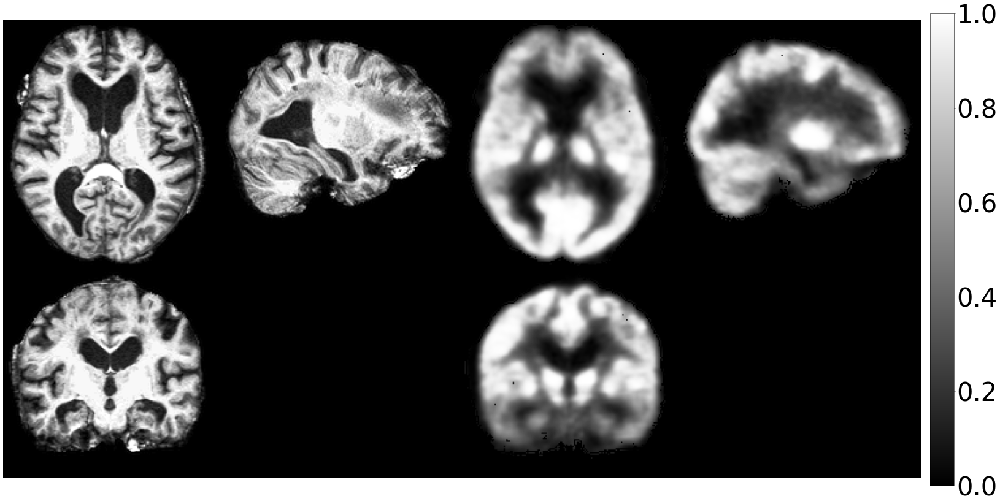

torch.Size([1, 1, 160, 192, 160])
torch.Size([1, 1, 160, 192, 160])


In [12]:
for batch in val_loader:
    image_1 = batch["mri"]
    label_1 = batch["pet"]
    names = batch["name"]  # Extract subject information

    # Print or visualize subject information
    for idx, name in enumerate(names):
        print(f"Subject name: {name}")

    compare_3d([image_1, label_1])
    break  # Uncomment to compare only the first batch
print(image_1.shape)
print(label_1.shape)


In [13]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model= DiffusionModelUNet(
    spatial_dims=3,
    in_channels=1,#1,
    out_channels=1,
    num_channels=(64,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model.to(device)
scheduler = DDPMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=1000)
optimizer= torch.optim.Adam(params=model.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)

# scheduler = DDIMScheduler(prediction_type='v_prediction',num_train_timesteps=1000,
#                            schedule="scaled_linear_beta",beta_start=0.0005, beta_end=0.0195)
# scheduler.set_timesteps(num_inference_steps=50)
# inferer = DiffusionInferer(scheduler)
# optimizer_1 = torch.optim.Adam(params=model_1.parameters(), lr=2.5e-5)



`torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
`torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.


Epoch 19: 100%|█████████| 800/800 [15:29<00:00,  1.16s/it, loss=0.015]


epoch: 20
learning rate: 2.5e-05
Saved all parameters!



100%|█████████████████████████████████████████████████████████████████████████████████| 1000/1000 [07:10<00:00,  2.32it/s]


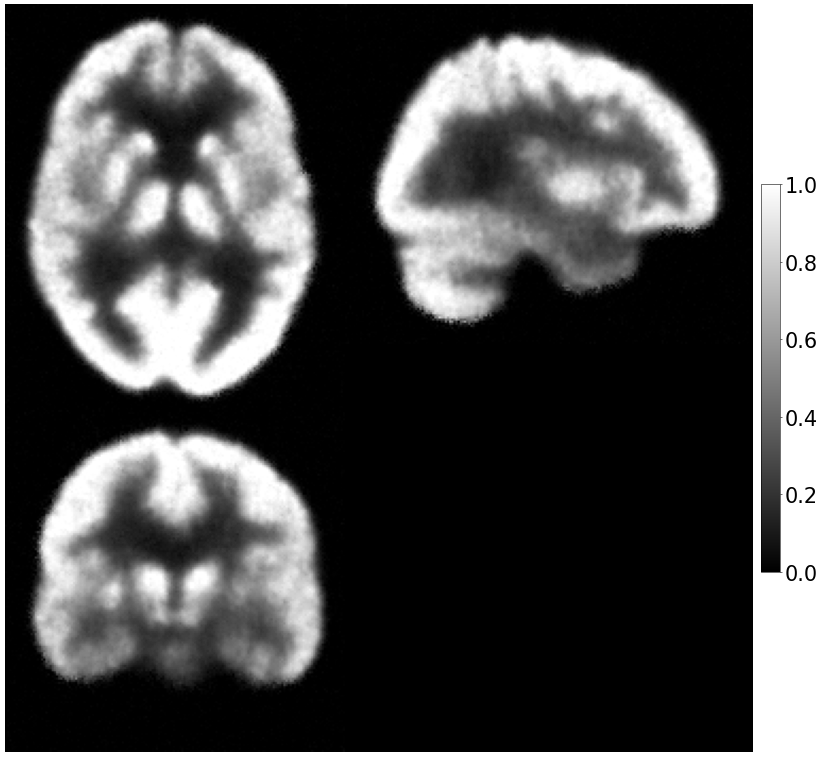

Epoch 29: 100%|████████| 800/800 [15:30<00:00,  1.16s/it, loss=0.0134]


epoch: 30
learning rate: 2.5e-05
Saved all parameters!



100%|█████████████████████████████████████████████████████████████████████████████████| 1000/1000 [07:10<00:00,  2.33it/s]


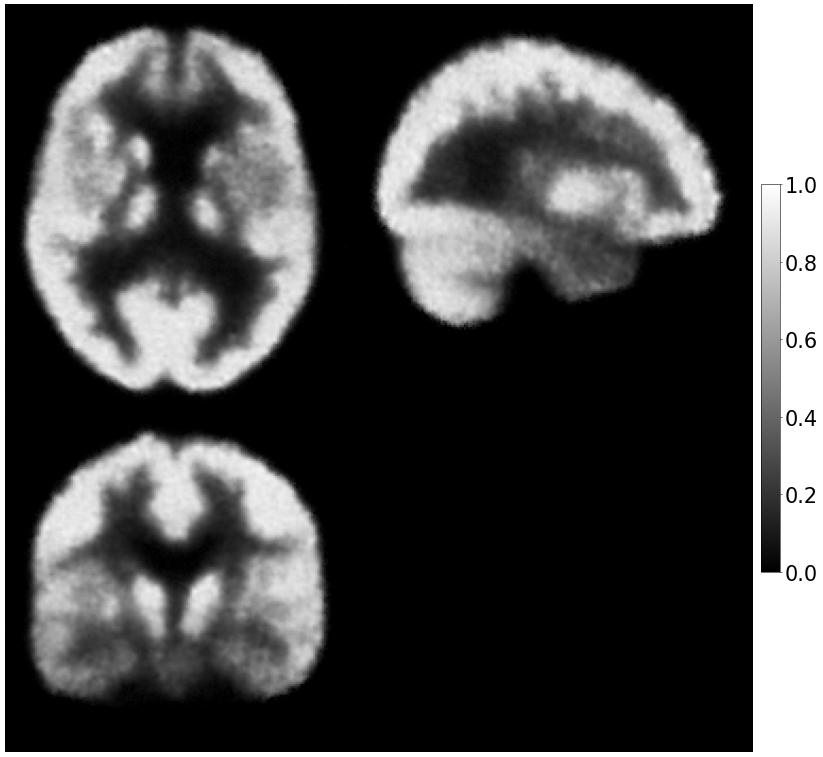

Epoch 32:  11%|▉        | 85/800 [01:40<14:01,  1.18s/it, loss=0.0125]


KeyboardInterrupt: 

In [14]:
import torch
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet_pretrained_clip'
checkpoint = torch.load(f'{checkpoint_dir}/first_part_10.pth', weights_only=True)

#checkpoint = torch.load(f'{checkpoint_dir}/first_part_10.pth')
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
start_epoch = checkpoint['epoch'] + 1  # 从上次停止的地方继续

# 设置新的训练参数
new_epochs = 90  # 继续训练的epoch数
total_epochs = start_epoch + new_epochs
val_interval = 10  # 验证间隔仍保持不变
epoch_loss_list = []  # 初始化epoch loss列表
val_epoch_loss_list = []  # 初始化验证epoch loss列表


n_epochs = 100
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()


for epoch in range(start_epoch, total_epochs):  # 修改循环范围
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, batch in progress_bar:
        images = batch["pet"].to(device)#mri
        pet_index = batch["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)

        with autocast(device_type='cuda',enabled=True):
            #noise = torch.randn_like(images).to(device)
            noise= donkey_noise_like(images).to(device)

            # Create timesteps
            #timesteps = torch.randint(0, inferer.scheduler.num_train_timesteps, (images.shape[0],), device=images.device).long()
            timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t
            target = inferer.scheduler.get_velocity(images, noise, timesteps)
            # Get model prediction
            noise_pred = inferer(inputs=images, diffusion_model=model, noise=noise, timesteps=timesteps,condition=pet_index)

            loss = F.mse_loss(noise_pred.float(), target.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
    epoch_loss_list.append(epoch_loss / (step + 1))

    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, batch in enumerate(val_loader):
            images = batch["pet"].to(device)
            pet_index = batch["pet_index"].to(device)
            # noise = torch.randn_like(images).to(device)
            noise= donkey_noise_like(images).to(device)
            
            with torch.no_grad():
                with autocast(device_type='cuda',enabled=True):
                    timesteps = torch.randint(0, 1000, (len(images),)).to(device)
                    # Get model prediction
                    target = inferer.scheduler.get_velocity(images, noise, timesteps)
                    noise_pred = inferer(inputs=images, diffusion_model=model, noise=noise, timesteps=timesteps,condition=pet_index)
                    val_loss = F.mse_loss(noise_pred.float(), target.float())

            val_epoch_loss += val_loss.item()
            progress_bar.set_postfix({"val_loss": val_epoch_loss / (step + 1)})
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
         #save checkpoints
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
             'model': model.state_dict(),
             'optimizer': optimizer.state_dict(),
             'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/first_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        
        # Sampling image during training
        #noise = torch.randn_like(images).to(device)
        noise= donkey_noise_like(images).to(device)
        with autocast(device_type='cuda',enabled=True):
            image = inferer.sample(input_noise=noise, diffusion_model=model, scheduler=scheduler,conditioning=pet_index)
        compare_3d([image])


In [ ]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler


n_epochs = 100
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet_pretrained_clip'


for epoch in range(n_epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, batch in progress_bar:
        images = batch["pet"].to(device)#mri
        pet_index = batch["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)

        with autocast(device_type='cuda',enabled=True):
            #noise = torch.randn_like(images).to(device)
            noise= donkey_noise_like(images).to(device)

            # Create timesteps
            #timesteps = torch.randint(0, inferer.scheduler.num_train_timesteps, (images.shape[0],), device=images.device).long()
            timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t
            target = inferer.scheduler.get_velocity(images, noise, timesteps)
            # Get model prediction
            noise_pred = inferer(inputs=images, diffusion_model=model, noise=noise, timesteps=timesteps,condition=pet_index)

            loss = F.mse_loss(noise_pred.float(), target.float())

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})
    epoch_loss_list.append(epoch_loss / (step + 1))

    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, batch in enumerate(val_loader):
            images = batch["pet"].to(device)
            pet_index = batch["pet_index"].to(device)
            # noise = torch.randn_like(images).to(device)
            noise= donkey_noise_like(images).to(device)
            
            with torch.no_grad():
                with autocast(device_type='cuda',enabled=True):
                    timesteps = torch.randint(0, 1000, (len(images),)).to(device)
                    # Get model prediction
                    target = inferer.scheduler.get_velocity(images, noise, timesteps)
                    noise_pred = inferer(inputs=images, diffusion_model=model, noise=noise, timesteps=timesteps,condition=pet_index)
                    val_loss = F.mse_loss(noise_pred.float(), target.float())

            val_epoch_loss += val_loss.item()
            progress_bar.set_postfix({"val_loss": val_epoch_loss / (step + 1)})
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))
         #save checkpoints
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
             'model': model.state_dict(),
             'optimizer': optimizer.state_dict(),
             'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/first_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        
        # Sampling image during training
        #noise = torch.randn_like(images).to(device)
        noise= donkey_noise_like(images).to(device)
        with autocast(device_type='cuda',enabled=True):
            image = inferer.sample(input_noise=noise, diffusion_model=model, scheduler=scheduler,conditioning=pet_index)
        compare_3d([image])


In [20]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model_1= DiffusionModelUNet(
    spatial_dims=3,
    in_channels=2,#1,
    out_channels=1,
    num_channels=(64,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model_1.to(device)
scheduler = DDPMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=1000)
optimizer_1= torch.optim.Adam(params=model_1.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)


In [21]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm

checkpoint_path = '/home/data/liutuo/code/checkpoint/mri2pet_pretrained_clip/first_part_30.pth'
source_weight=torch.load(checkpoint_path)["model"]
model_state_dict=model_1.state_dict()
for key in model_state_dict.keys():
    #if key in target_weight.keys():
    if model_state_dict[key].shape==source_weight[key].shape:
        model_state_dict[key]=source_weight[key]
    else:
        # expand dims with copied value
        print(f"{key} shape dismatch: source {model_state_dict[key].shape}, target {source_weight[key].shape}")
        repeat_times=[yy//xx for yy,xx in zip(model_state_dict[key].shape,source_weight[key].shape)]
        model_state_dict[key]=source_weight[key].repeat(repeat_times)

model_1.load_state_dict(model_state_dict)
model_1.to(device)

conv_in.conv.weight shape dismatch: source torch.Size([64, 2, 3, 3, 3]), target torch.Size([64, 1, 3, 3, 3])


You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


DiffusionModelUNet(
  (conv_in): Convolution(
    (conv): Conv3d(2, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  )
  (time_embed): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
  )
  (down_blocks): ModuleList(
    (0-2): 3 x DownBlock(
      (resnets): ModuleList(
        (0): ResnetBlock(
          (norm1): GroupNorm(32, 64, eps=1e-06, affine=True)
          (nonlinearity): SiLU()
          (conv1): Convolution(
            (conv): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          )
          (time_emb_proj): Linear(in_features=256, out_features=64, bias=True)
          (norm2): GroupNorm(32, 64, eps=1e-06, affine=True)
          (conv2): Convolution(
            (conv): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          )
          (skip_connection): Identity()
        )
      )
      (downsa

Epoch 9: 100%|█████████| 800/800 [15:33<00:00,  1.17s/it, loss=0.0126]


Epoch 10 Validation loss 0.011219978470519457
epoch: 10
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


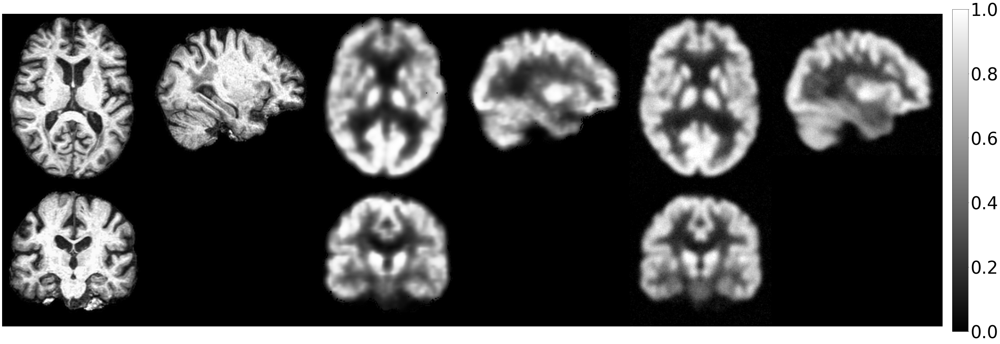

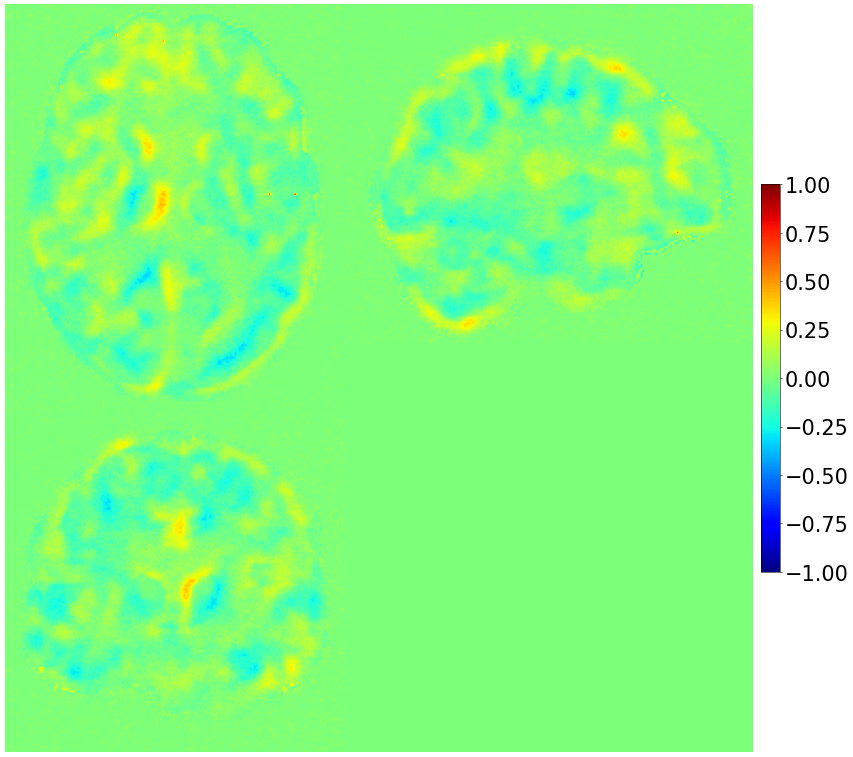

SSIM: 0.618857204914093
PSNR: 22.92751121520996


Epoch 19: 100%|████████| 800/800 [15:30<00:00,  1.16s/it, loss=0.0105]


Epoch 20 Validation loss 0.010277292466832828
epoch: 20
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


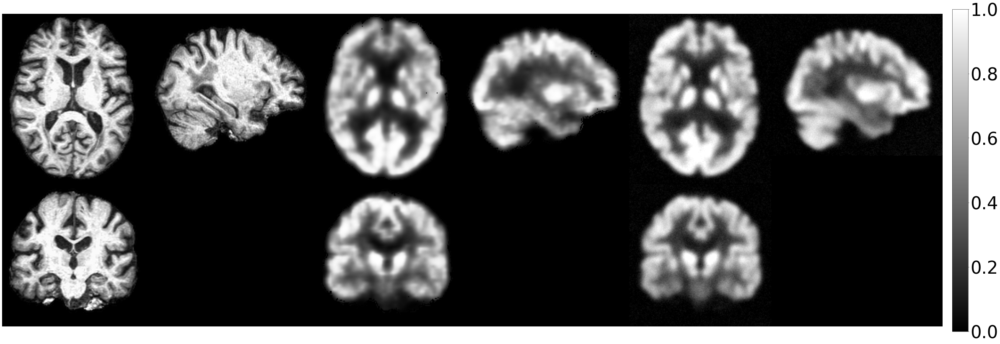

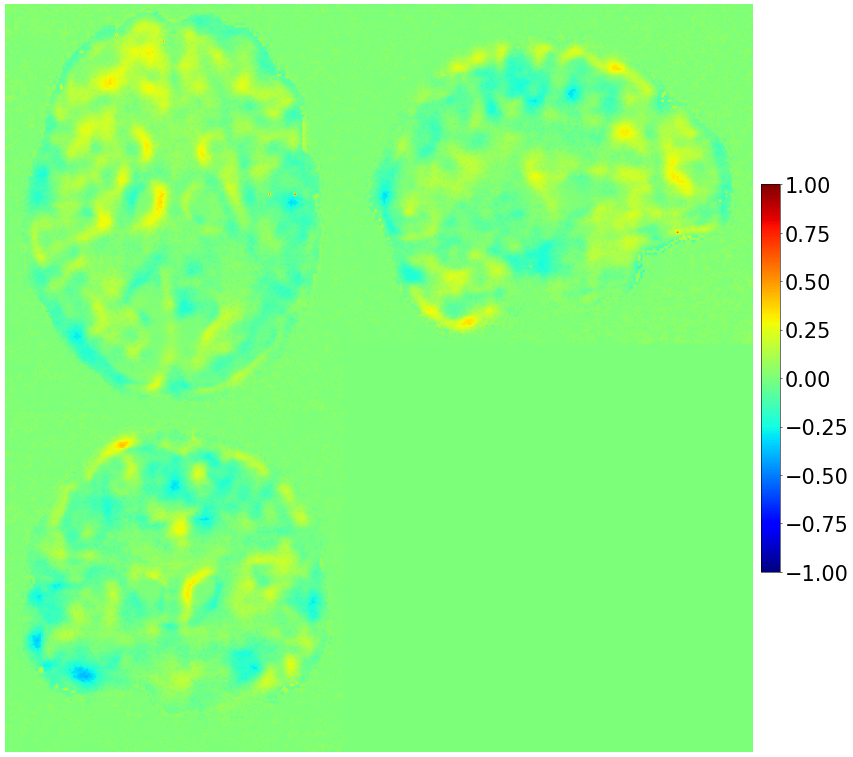

SSIM: 0.5133965611457825
PSNR: 23.747098922729492


Epoch 29: 100%|███████| 800/800 [15:28<00:00,  1.16s/it, loss=0.00935]


Epoch 30 Validation loss 0.011365203817423127
epoch: 30
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


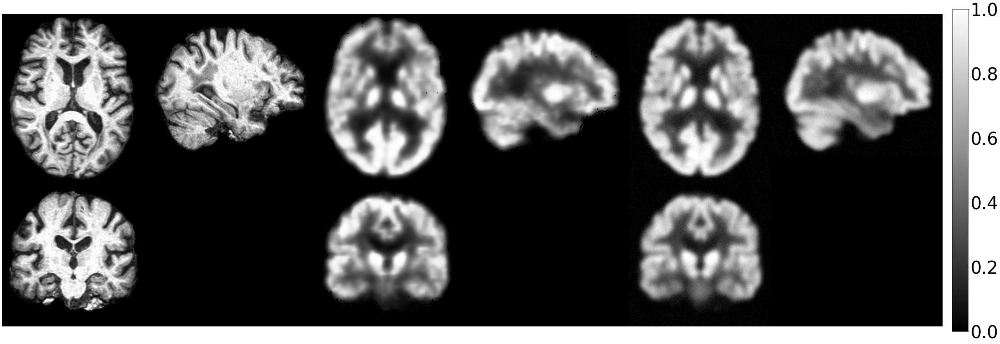

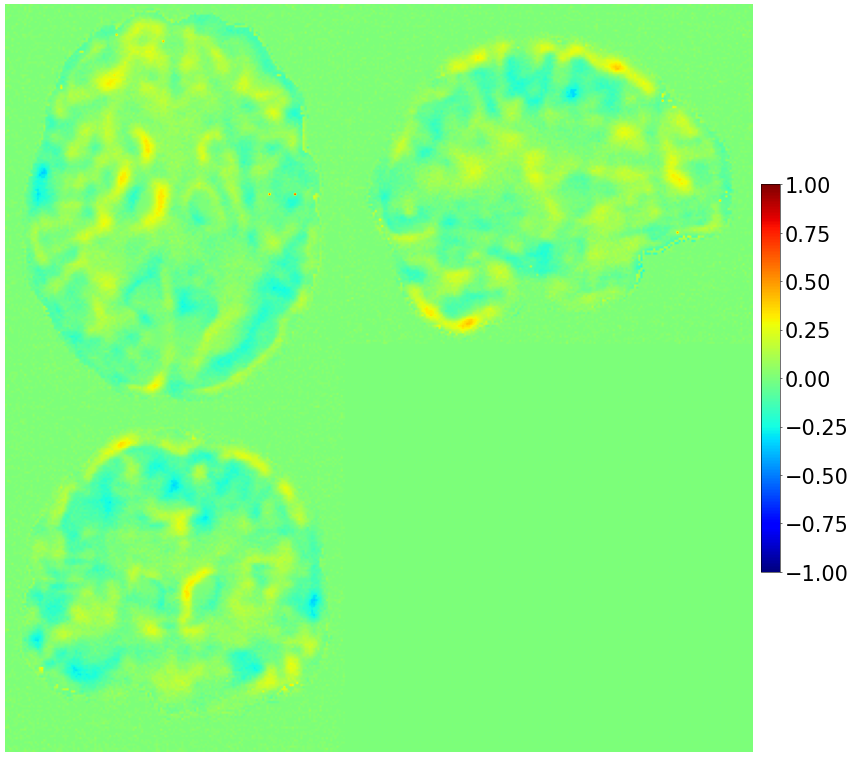

SSIM: 0.6001627445220947
PSNR: 23.884132385253906


Epoch 39: 100%|███████| 800/800 [15:33<00:00,  1.17s/it, loss=0.00915]


Epoch 40 Validation loss 0.014717852495791883
epoch: 40
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


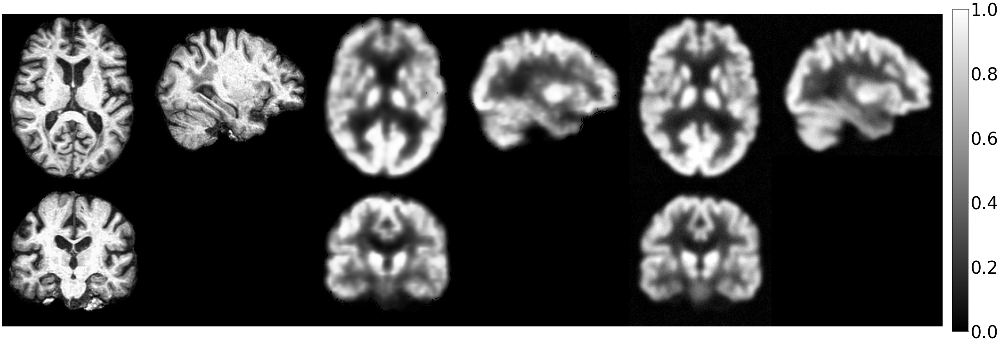

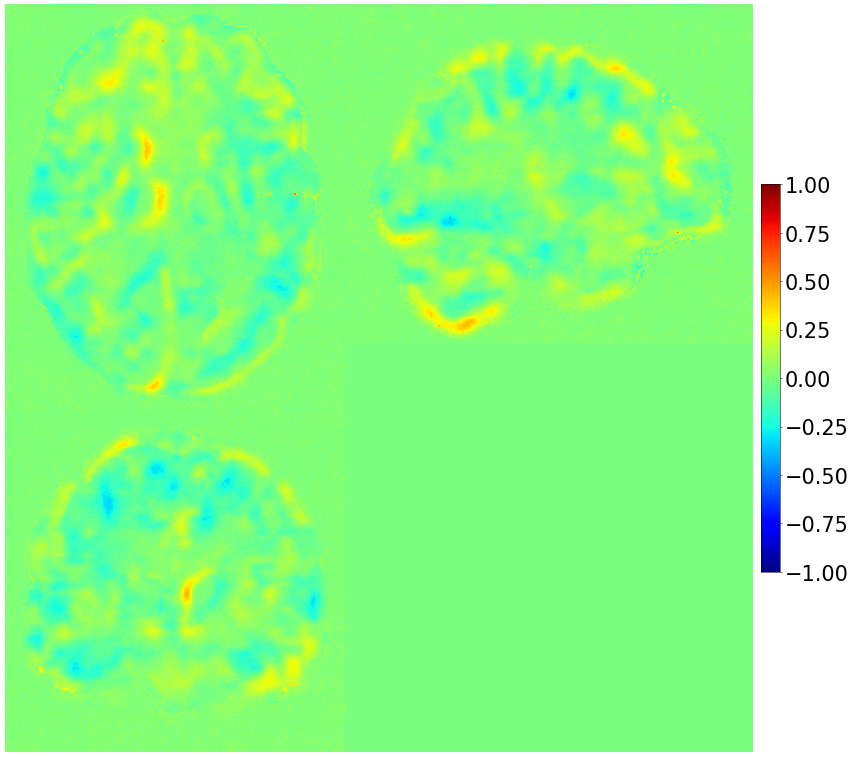

SSIM: 0.5231497287750244
PSNR: 22.921140670776367


Epoch 49: 100%|███████| 800/800 [15:30<00:00,  1.16s/it, loss=0.00782]


Epoch 50 Validation loss 0.013418195493190937
epoch: 50
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


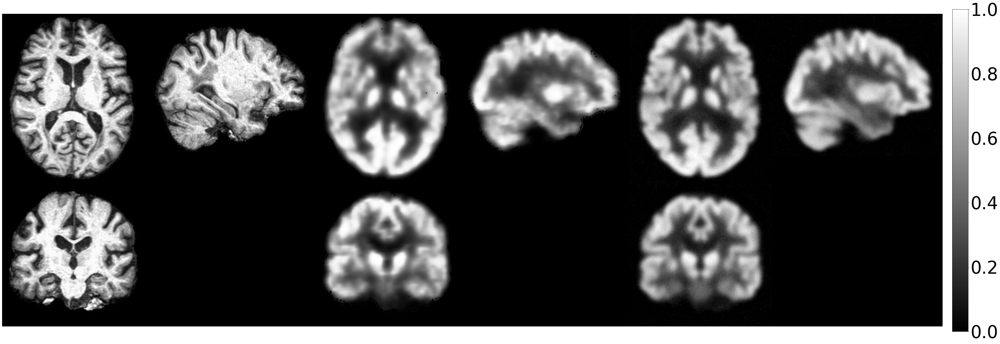

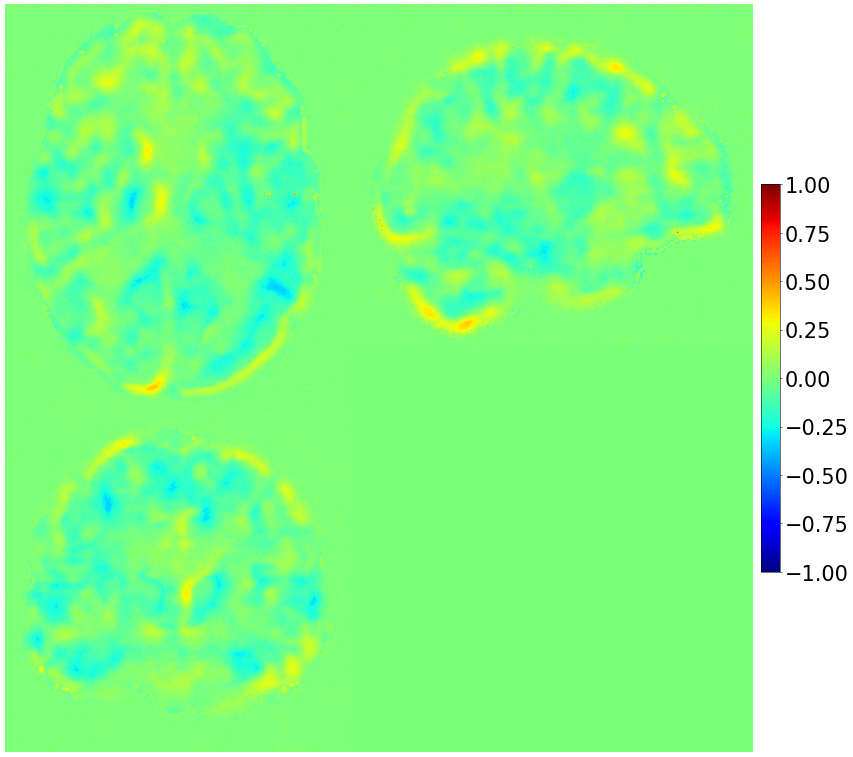

SSIM: 0.766891598701477
PSNR: 22.866371154785156


Epoch 59: 100%|████████| 800/800 [15:30<00:00,  1.16s/it, loss=0.0077]


Epoch 60 Validation loss 0.009287597821023327
epoch: 60
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


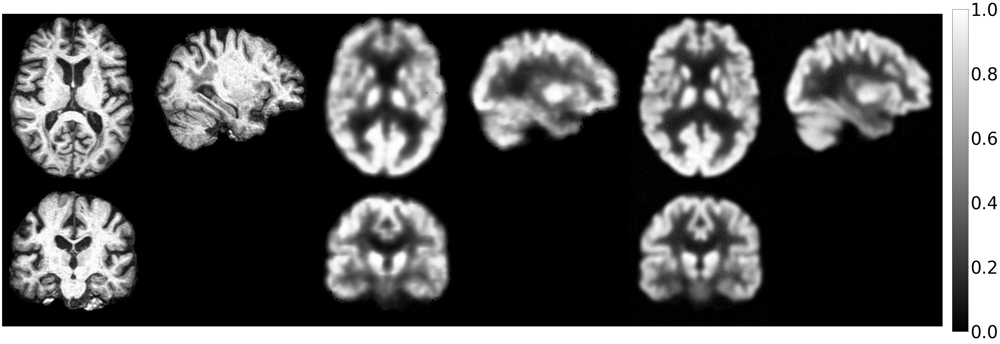

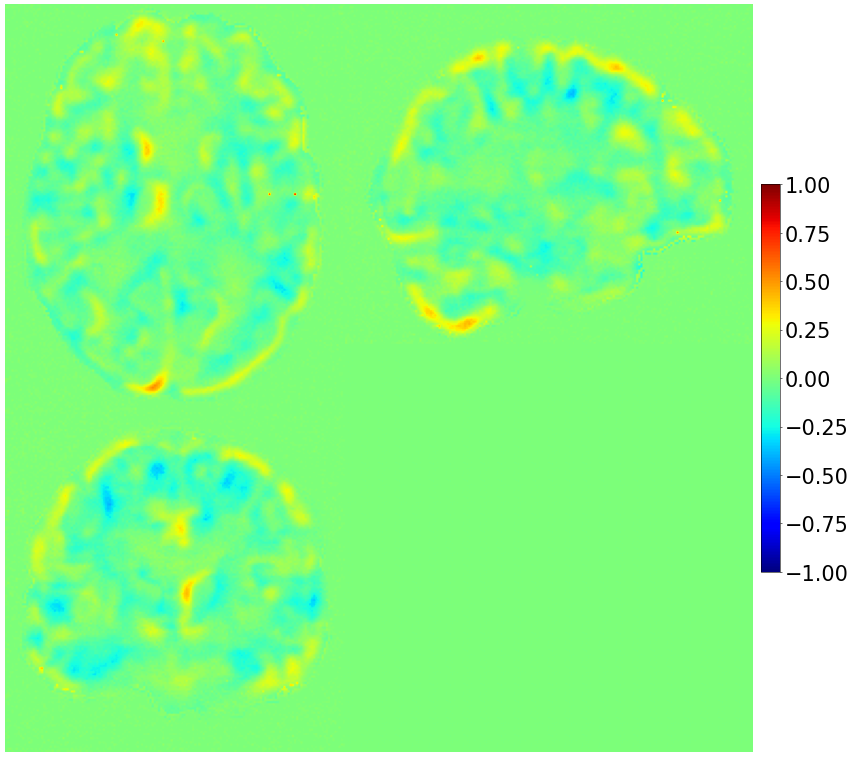

SSIM: 0.6986242532730103
PSNR: 23.013641357421875


Epoch 69: 100%|███████| 800/800 [15:29<00:00,  1.16s/it, loss=0.00777]


Epoch 70 Validation loss 0.009207129083562495
epoch: 70
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


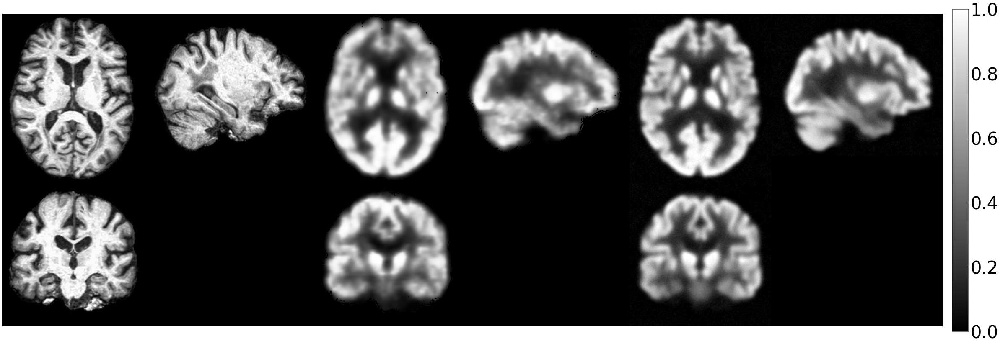

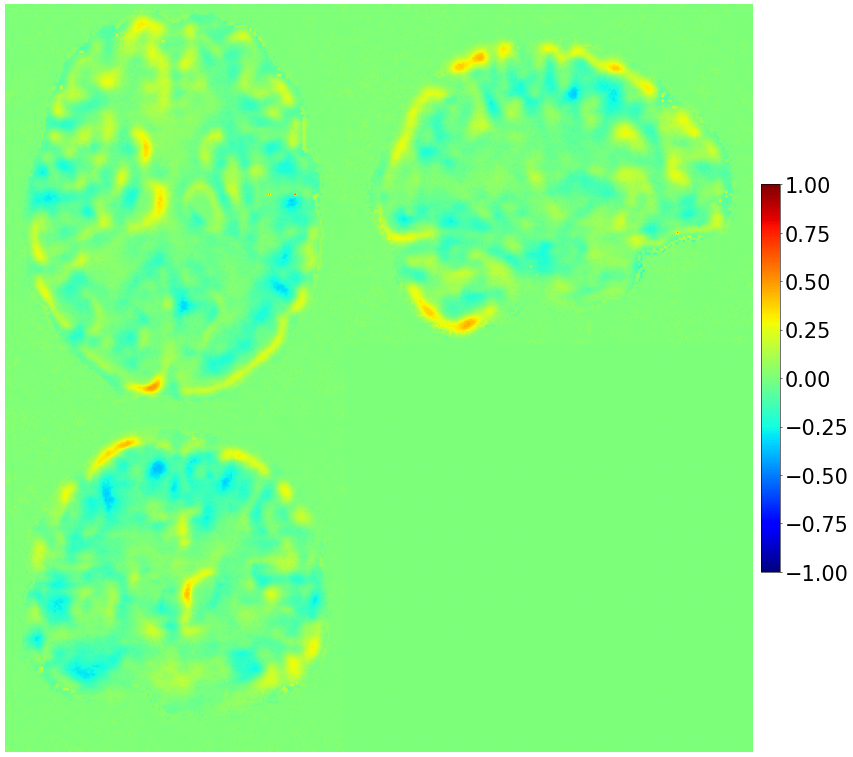

SSIM: 0.6158791780471802
PSNR: 22.870769500732422


Epoch 79: 100%|███████| 800/800 [15:28<00:00,  1.16s/it, loss=0.00799]


Epoch 80 Validation loss 0.010326661199252022
epoch: 80
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


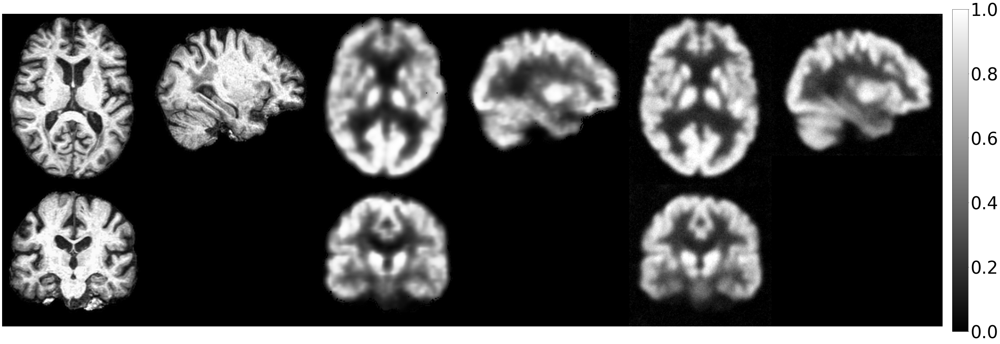

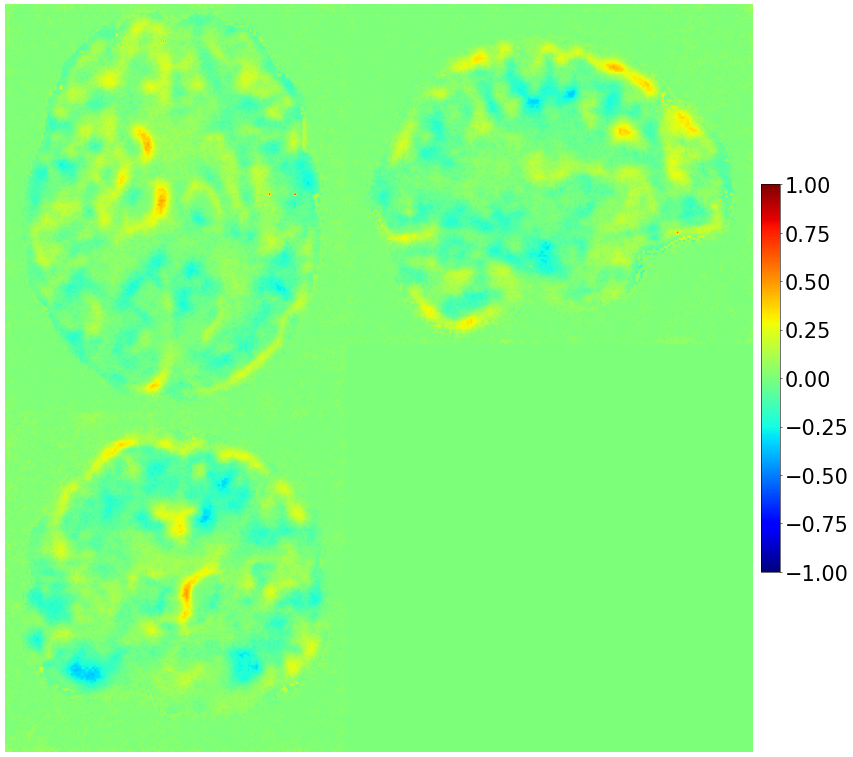

SSIM: 0.5778298377990723
PSNR: 23.35771942138672


Epoch 89: 100%|███████| 800/800 [15:30<00:00,  1.16s/it, loss=0.00671]


Epoch 90 Validation loss 0.008293094205469075
epoch: 90
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


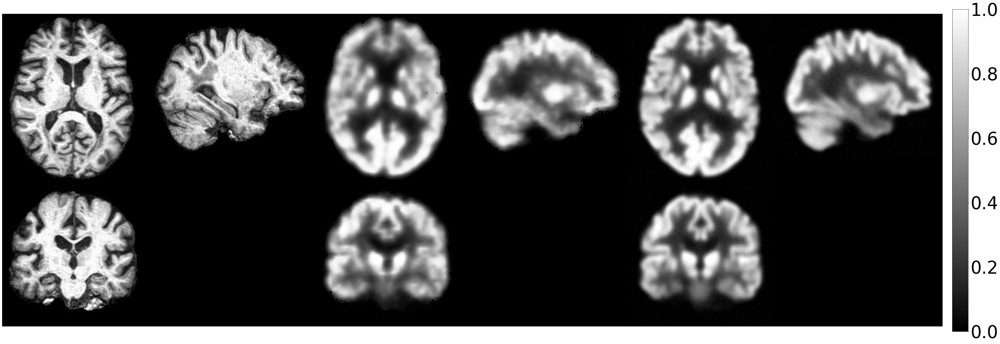

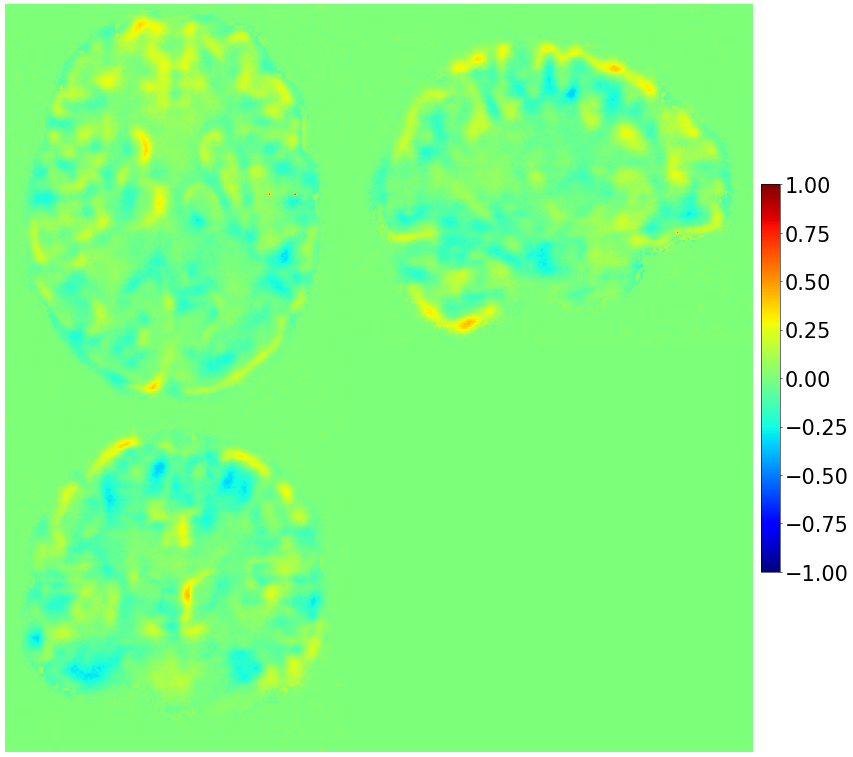

SSIM: 0.7533949017524719
PSNR: 23.548357009887695


Epoch 99: 100%|███████| 800/800 [15:30<00:00,  1.16s/it, loss=0.00627]


Epoch 100 Validation loss 0.00966730282718378
epoch: 100
learning rate: 2.5e-05
Saved all parameters!

torch.Size([1, 1, 160, 192, 160])
tensor(999)


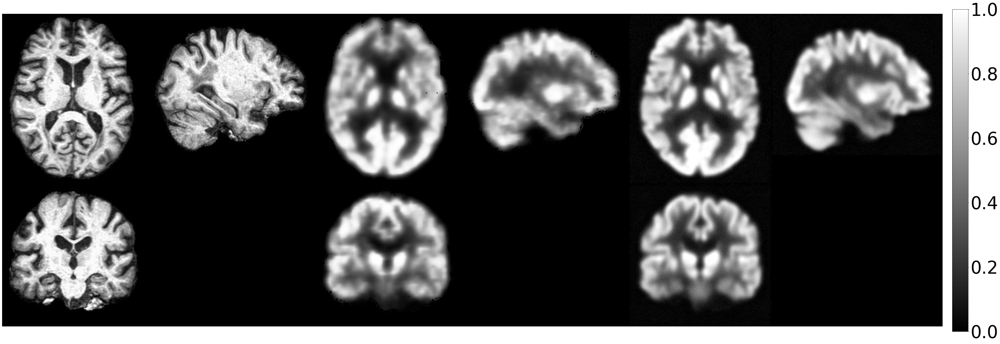

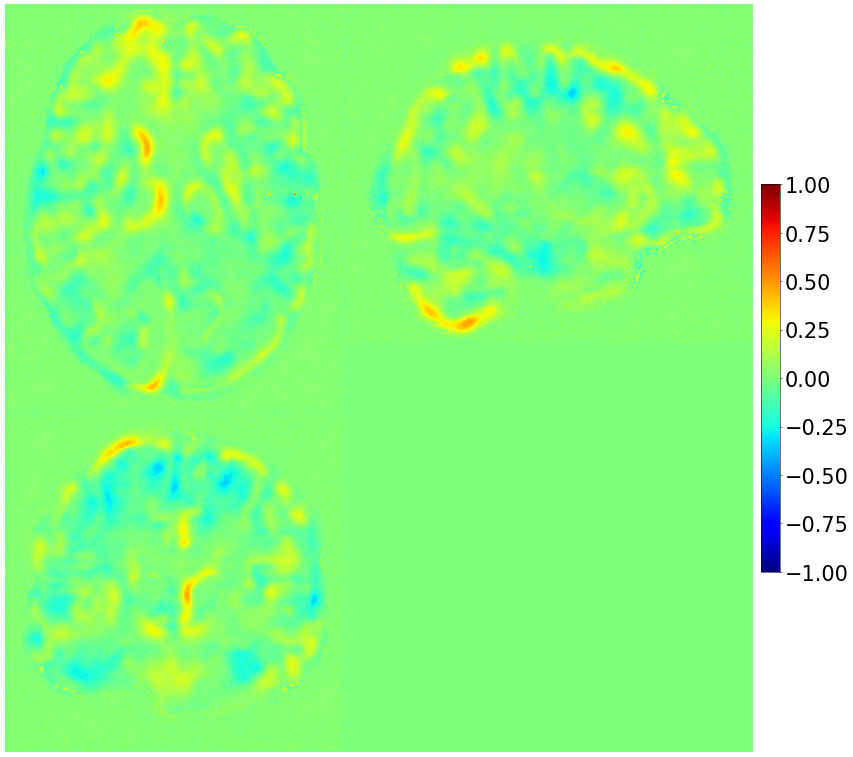

SSIM: 0.4495238661766052
PSNR: 23.080841064453125


In [32]:
import os
import tempfile
import time
from liutuo_utils import donkey_noise_like
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from monai import transforms
from monai.apps import DecathlonDataset
from monai.config import print_config
from monai.data import DataLoader
from monai.utils import set_determinism
from torch.cuda.amp import GradScaler, autocast
from tqdm import tqdm
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler





n_epochs = 100
val_interval =10
epoch_loss_list = []
val_epoch_loss_list = []
scaler = GradScaler()  
total_start = time.time()
checkpoint_dir = '/home/data/liutuo/code/checkpoint/mri2pet_pretrained_clip'

for epoch in range(n_epochs):
    model_1.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device)  # this is the ground truth segmentation
        pet_index = data["pet_index"].to(device)
        optimizer_1.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t

        with autocast(device_type='cuda', enabled=True):
            noise = donkey_noise_like(images).to(device)
            #noise = torch.randn_like(images).to(device)
            noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
            combined = torch.cat((images, noisy_seg), dim=1)
            target = inferer.scheduler.get_velocity(seg, noise, timesteps)

            prediction = model_1(x=combined, timesteps=timesteps,context=pet_index)
            loss = F.mse_loss(prediction.float(), target.float())
        scaler.scale(loss).backward()
        scaler.step(optimizer_1)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})

    epoch_loss_list.append(epoch_loss / (step + 1))

    if (epoch + 1) % val_interval == 0:
        model_1.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)
            pet_index = data_val["pet_index"].to(device)
            timesteps = torch.randint(0, 1000, (len(images),)).to(device)

            with torch.no_grad():
                with autocast(device_type='cuda', enabled=True):
                    noise = donkey_noise_like(images).to(device)
                    noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
                    combined = torch.cat((images, noisy_seg), dim=1)
                    target = inferer.scheduler.get_velocity(seg, noise, timesteps)
                    prediction = model_1(x=combined, timesteps=timesteps,context=pet_index)
                    val_loss = F.mse_loss(prediction.float(), target.float())
            val_epoch_loss += val_loss.item()

        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))

        # 保存模型和优化器状态
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer_1.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model_1.state_dict(),
            'optimizer': optimizer_1.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        # 采样过程
        model_1.eval()
        input_img = images.to(device)
        print(input_img.shape)
        noise= donkey_noise_like(images).to(device)
        current_img = noise  # for the segmentation mask, we start from random noise.
        combined = torch.cat((input_img, noise), dim=1)  # We concatenate the input brain MR image to add anatomical information.
        
        #scheduler.set_timesteps(num_inference_steps=1000)
        
        # progress_bar = tqdm(scheduler.timesteps)
        # for t in progress_bar:  # go through the noising process
        #     with autocast(device_type='cuda', enabled=True):
        #         with torch.no_grad():
        #             model_output = model_1(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
        #             current_img, img0 = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
        #             combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information
        t = scheduler.timesteps[0]
        print(t)
        with autocast(device_type='cuda', enabled=True):
            with torch.no_grad():
                model_output = model_1(combined, timesteps=torch.Tensor((t,)).to(current_img.device), context=pet_index)
                current_img, img0 = scheduler.step(model_output, t, current_img)
        
        current_img =img0.to('cpu')
        labels = seg.to('cpu')
        compare_3d([input_img,labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
        psnr_metric=PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 


In [ ]:
# 加载上次训练的模型和优化器状态
checkpoint = torch.load(f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_160.pth')
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
start_epoch = checkpoint['epoch'] + 1  # 从上次停止的地方继续

# 设置新的训练参数
new_epochs = 40  # 继续训练的epoch数
total_epochs = start_epoch + new_epochs
val_interval = 10  # 验证间隔仍保持不变
epoch_loss_list = []  # 初始化epoch loss列表
val_epoch_loss_list = []  # 初始化验证epoch loss列表

for epoch in range(start_epoch, total_epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device)  # this is the ground truth segmentation
        pet_index = data["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t

        with autocast(device_type='cuda', enabled=True):
            noise = donkey_noise_like(images).to(device)
            #noise = torch.randn_like(images).to(device)
            noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
            combined = torch.cat((images, noisy_seg), dim=1)
            target = inferer.scheduler.get_velocity(seg, noise, timesteps)

            prediction = model(x=combined, timesteps=timesteps)
            loss = F.mse_loss(prediction.float(), target.float())
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})

    epoch_loss_list.append(epoch_loss / (step + 1))

    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)
            pet_index = data_val["pet_index"].to(device)
            timesteps = torch.randint(0, 1000, (len(images),)).to(device)

            with torch.no_grad():
                with autocast(device_type='cuda', enabled=True):
                    noise = donkey_noise_like(images).to(device)
                    noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
                    combined = torch.cat((images, noisy_seg), dim=1)
                    target = inferer.scheduler.get_velocity(seg, noise, timesteps)
                    prediction = model(x=combined, timesteps=timesteps)
                    val_loss = F.mse_loss(prediction.float(), target.float())
            val_epoch_loss += val_loss.item()

        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))

        # 保存模型和优化器状态
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
         # Saving model parameters
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        # 采样过程
        model.eval()
        input_img = image_1.to(device)
        print(input_img.shape)
        noise= donkey_noise_like(images).to(device)
        current_img = noise  # for the segmentation mask, we start from random noise.
        combined = torch.cat((input_img, noise), dim=1)  # We concatenate the input brain MR image to add anatomical information.
        
        #scheduler.set_timesteps(num_inference_steps=1000)
        progress_bar = tqdm(scheduler.timesteps)
        for t in progress_bar:  # go through the noising process
            with autocast(device_type='cuda', enabled=True):
                with torch.no_grad():
                    model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device))
                    current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                    combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information

        current_img = current_img.to('cpu')
        labels = label_1.to('cpu')
        compare_3d([input_img,labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=7)
        psnr_metric=PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 


In [ ]:
for batch in train_loader:
    image_1 = batch["mri"]
    label_1= batch["pet"]
    names = batch["name"]  # Extract subject information

    # Print or visualize subject information
    for idx, name in enumerate(names):
        print(f"Subject name: {name}")

    compare_3d([image_1, label_1])
    break  # Uncomment to compare only the first batch
print(image_1.shape)
print(label_1.shape)


In [ ]:
# 加载上次训练的模型和优化器状态
checkpoint = torch.load(f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_340.pth')
model.load_state_dict(checkpoint['model'])
optimizer.load_state_dict(checkpoint['optimizer'])
start_epoch = checkpoint['epoch'] + 1  # 从上次停止的地方继续

# 设置新的训练参数
new_epochs =20  # 继续训练的epoch数
total_epochs = start_epoch + new_epochs
val_interval = 1  # 验证间隔仍保持不变
epoch_loss_list = []  # 初始化epoch loss列表
val_epoch_loss_list = []  # 初始化验证epoch loss列表

for epoch in range(start_epoch, total_epochs):
    model.train()
    epoch_loss = 0
    progress_bar = tqdm(enumerate(train_loader), total=len(train_loader), ncols=70)
    progress_bar.set_description(f"Epoch {epoch}")
    for step, data in progress_bar:
        images = data["mri"].to(device)
        seg = data["pet"].to(device)  # this is the ground truth segmentation
        pet_index = data["pet_index"].to(device)
        optimizer.zero_grad(set_to_none=True)
        timesteps = torch.randint(0, 1000, (len(images),)).to(device)  # pick a random time step t

        with autocast(device_type='cuda', enabled=True):
            noise = donkey_noise_like(images).to(device)
            #noise = torch.randn_like(images).to(device)
            noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
            combined = torch.cat((images, noisy_seg), dim=1)
            target = inferer.scheduler.get_velocity(seg, noise, timesteps)

            prediction = model(x=combined, timesteps=timesteps, context=pet_index)
            loss = F.mse_loss(prediction.float(), target.float())
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        epoch_loss += loss.item()
        progress_bar.set_postfix({"loss": epoch_loss / (step + 1)})

    epoch_loss_list.append(epoch_loss / (step + 1))

    if (epoch + 1) % val_interval == 0:
        model.eval()
        val_epoch_loss = 0
        for step, data_val in enumerate(val_loader):
            images = data_val["mri"].to(device)
            seg = data_val["pet"].to(device)
            pet_index = data_val["pet_index"].to(device)
            timesteps = torch.randint(0, 1000, (len(images),)).to(device)

            with torch.no_grad():
                with autocast(device_type='cuda', enabled=True):
                    noise = donkey_noise_like(images).to(device)
                    noisy_seg = scheduler.add_noise(original_samples=seg, noise=noise, timesteps=timesteps)
                    combined = torch.cat((images, noisy_seg), dim=1)
                    target = inferer.scheduler.get_velocity(seg, noise, timesteps)
                    prediction = model(x=combined, timesteps=timesteps, context=pet_index)
                    val_loss = F.mse_loss(prediction.float(), target.float())
            val_epoch_loss += val_loss.item()

        print("Epoch", epoch + 1, "Validation loss", val_epoch_loss / (step + 1))
        val_epoch_loss_list.append(val_epoch_loss / (step + 1))

        # 保存模型和优化器状态
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
         # Saving model parameters
        print('epoch:', epoch + 1)
        print('learning rate:', optimizer.state_dict()['param_groups'][0]['lr'])
        checkpoint = {
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'epoch': epoch
        }
        torch.save(checkpoint, f'{checkpoint_dir}/noise2image about mri2pet_method_two_second_part_{epoch + 1}.pth')
        print('Saved all parameters!\n')
        
        # 采样过程
        model.eval()
        input_img = image_1.to(device)
        print(input_img.shape)
        noise= donkey_noise_like(images).to(device)
        #noise = torch.randn_like(images).to(device)
        current_img = noise  # for the segmentation mask, we start from random noise.
        combined = torch.cat((input_img, noise), dim=1)  # We concatenate the input brain MR image to add anatomical information.
        
        #scheduler.set_timesteps(num_inference_steps=1000)
        progress_bar = tqdm(scheduler.timesteps)
        for t in progress_bar:  # go through the noising process
            with autocast(device_type='cuda', enabled=True): #with autocast(device_type='cuda', enabled=False):
                with torch.no_grad():
                    model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
                    current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                    combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information

        current_img = current_img.to('cpu')
        labels = label_1.to('cpu')
        compare_3d([input_img,labels, current_img])
        compare_3d_jet([current_img - labels])
        from generative.metrics import SSIMMetric
        from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
        ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=11)
        psnr_metric=PSNRMetric(1.0)

        ssim_value = ssim_metric(labels, current_img)
        psnr_value = psnr_metric(labels, current_img)

        print(f"SSIM: {ssim_value.mean().item()}")
        print(f"PSNR: {psnr_value.mean().item()}") 


In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint = torch.load('/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_concat_final/noise2image about mri2pet_method_two_second_part_120.pth')
model.load_state_dict(checkpoint['model'])

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=11)

# 用于存储10次采样的SSIM值
ssim_values = []

# 使用不同输入图像进行10次采样
for i, data in enumerate(train_loader):
    if i >= 100:  # 只采样10次
        break
    
    # 获取不同的输入图像和标签
    input_img = data["mri"].to(device)
    labels = data["pet"].to(device)
    pet_index = data["pet_index"].to(device)

    # 生成随机噪声并初始化采样图像
    noise = donkey_noise_like(input_img).to(device)
    current_img = noise  # 从随机噪声开始
    combined = torch.cat((input_img, noise), dim=1)  # 拼接MR图像和噪声


    progress_bar = tqdm(scheduler.timesteps, desc=f"Sampling {i+1}")
    for t in progress_bar:  # go through the noising process
        with autocast(device_type='cuda', enabled=True):
            with torch.no_grad():
                model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
                current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information


    # 将结果移回CPU
    current_img = current_img.to('cpu')
    labels = labels.to('cpu')
    

    # 计算当前采样的SSIM并存储
    ssim_value = ssim_metric(labels, current_img)
    ssim_values.append(ssim_value.mean().item())

    # 可视化采样结果
    compare_3d([input_img, labels, current_img])
    compare_3d_jet([current_img - labels])
    from generative.metrics import SSIMMetric
    from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
    ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=11)
    psnr_metric=PSNRMetric(1.0)

    ssim_value = ssim_metric(labels, current_img)
    psnr_value = psnr_metric(labels, current_img)

    print(f"SSIM: {ssim_value.mean().item()}")
    print(f"PSNR: {psnr_value.mean().item()}") 

# 计算SSIM的均值和方差
ssim_mean = np.mean(ssim_values)
ssim_variance = np.var(ssim_values)

# 输出结果
print(f"SSIM均值: {ssim_mean}")
print(f"SSIM方差: {ssim_variance}")


In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint = torch.load('/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_concat_test/noise2image about mri2pet_method_two_second_part_344.pth')
model.load_state_dict(checkpoint['model'])

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=11)

# 用于存储10次采样的SSIM值
ssim_values = []

# 使用不同输入图像进行10次采样
for i, data in enumerate(train_loader):
    if i >= 20:  # 只采样10次
        break
    
    # 获取不同的输入图像和标签
    input_img = data["mri"].to(device)
    labels = data["pet"].to(device)
    pet_index = data["pet_index"].to(device)

    # 生成随机噪声并初始化采样图像
    noise = donkey_noise_like(input_img).to(device)
    current_img = noise  # 从随机噪声开始
    combined = torch.cat((input_img, noise), dim=1)  # 拼接MR图像和噪声


    progress_bar = tqdm(scheduler.timesteps, desc=f"Sampling {i+1}")
    for t in progress_bar:  # go through the noising process
        with autocast(device_type='cuda', enabled=True):
            with torch.no_grad():
                model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
                current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information


    # 将结果移回CPU
    current_img = current_img.to('cpu')
    labels = labels.to('cpu')
    

    # 计算当前采样的SSIM并存储
    ssim_value = ssim_metric(labels, current_img)
    ssim_values.append(ssim_value.mean().item())

    # 可视化采样结果
    compare_3d([input_img, labels, current_img])
    compare_3d_jet([current_img - labels])
    from generative.metrics import SSIMMetric
    from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
    ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=11)
    psnr_metric=PSNRMetric(1.0)

    ssim_value = ssim_metric(labels, current_img)
    psnr_value = psnr_metric(labels, current_img)

    print(f"SSIM: {ssim_value.mean().item()}")
    print(f"PSNR: {psnr_value.mean().item()}") 

# 计算SSIM的均值和方差
ssim_mean = np.mean(ssim_values)
ssim_variance = np.var(ssim_values)

# 输出结果
print(f"SSIM均值: {ssim_mean}")
print(f"SSIM方差: {ssim_variance}")


In [ ]:
for batch in val_loader:
    
    images = batch["mri"]
    
    labels = batch["pet"]
    
    compare_3d([images, labels])
#     break  # 只比较第一个批次的数据
print(images.shape)
print(labels.shape)


In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint = torch.load('/home/ssd/liutuo/checkpoint/mri2pet/mri2pet small data number->add personal clip->concat/noise2image about mri2pet_method_two_second_part_140.pth')
model.load_state_dict(checkpoint['model'])

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=7)

# 用于存储10次采样的SSIM值
ssim_values = []

# 使用同一张输入图像进行10次采样
input_img = next(iter(val_loader))["mri"].to(device)
labels = next(iter(val_loader))["pet"].to(device)
pet_index = next(iter(val_loader))["pet_index"].to(device)

for i in range(10):
    # 生成随机噪声并初始化采样图像
    noise = donkey_noise_like(input_img).to(device)
    current_img = noise  # 从随机噪声开始
    combined = torch.cat((input_img, noise), dim=1)  # 拼接MR图像和噪声

    
    progress_bar = tqdm(scheduler.timesteps, desc=f"Sampling {i+1}/10")
    for t in progress_bar:  # go through the noising process
        with autocast(enabled=False):
            with torch.no_grad():
                model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
                current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information


    # 将结果移回CPU
    current_img = current_img.to('cpu')
    labels_cpu = labels.to('cpu')

    # 计算当前采样的SSIM并存储
    ssim_value = ssim_metric(labels_cpu, current_img)
    ssim_values.append(ssim_value.mean().item())

    # 可视化采样结果
    print(f"Sampling {i+1}:")
    compare_3d([input_img.to('cpu'), labels_cpu, current_img])
    compare_3d_jet([current_img - labels_cpu])

# 计算SSIM的均值和方差
ssim_mean = np.mean(ssim_values)
ssim_variance = np.var(ssim_values)

# 输出结果
print(f"SSIM均值: {ssim_mean}")
print(f"SSIM方差: {ssim_variance}")


In [ ]:
print(current_img.shape)

In [ ]:
import SimpleITK as sitk
import os

# 定义保存路径
save_dir = "/home/ssd/liutuo/look_images"
os.makedirs(save_dir, exist_ok=True)

# 将张量去掉 Batch 和 Channel 维度，转换为 (D, H, W)
labels_np = labels_cpu.squeeze().numpy()  # 去掉多余的维度，形状为 (80, 96, 80)
current_img_np = current_img.squeeze().numpy()  # 形状为 (80, 96, 80)

# 将 NumPy 数组转换为 SimpleITK 图像
labels_sitk = sitk.GetImageFromArray(labels_np)
current_img_sitk = sitk.GetImageFromArray(current_img_np)

# 保存为.nii.gz文件
labels_sitk_path = os.path.join(save_dir, "labels_cpu.nii.gz")
current_img_sitk_path = os.path.join(save_dir, "current_img.nii.gz")

sitk.WriteImage(labels_sitk, labels_sitk_path)
sitk.WriteImage(current_img_sitk, current_img_sitk_path)

print(f"labels_cpu 已保存至 {labels_sitk_path}")
print(f"current_img 已保存至 {current_img_sitk_path}")


In [ ]:
import os
import SimpleITK as sitk
from skimage import exposure
import numpy as np

def match_histograms_and_save(target_image_path, reference_image_path, output_image_path):
    # 读取目标图像和参考图像
    target_img = sitk.ReadImage(target_image_path, sitk.sitkFloat32)
    reference_img = sitk.ReadImage(reference_image_path, sitk.sitkFloat32)

    # 获取图像数据
    target_data = sitk.GetArrayFromImage(target_img)
    reference_data = sitk.GetArrayFromImage(reference_img)

    # 进行直方图匹配
    matched_data = np.zeros_like(target_data)
    for i in range(target_data.shape[2]):
        target_slice = target_data[:, :, i]
        reference_slice = reference_data[:, :, i]
        matched_slice = exposure.match_histograms(target_slice, reference_slice)
        matched_data[:, :, i] = matched_slice

    # 创建新的图像
    matched_img = sitk.GetImageFromArray(matched_data)
    matched_img.CopyInformation(target_img)

    # 保存匹配后的图像
    sitk.WriteImage(matched_img, output_image_path)
    print(f"匹配后的图像已保存到 {output_image_path}")

def process_folder(folder_path):
    # 获取文件夹中的所有文件
    files = os.listdir(folder_path)
    
    # 过滤出以Pre开头和以GT开头的文件
    pre_files = [f for f in files if f.startswith('Pre_')]
    gt_files = [f for f in files if f.startswith('GT_')]
    
    # 创建一个字典来匹配Pre和GT文件
    gt_dict = {f.replace('GT', ''): f for f in gt_files}
    
    for pre_file in pre_files:
        base_name = pre_file.replace('Pre', '')
        if base_name in gt_dict:
            target_image_path = os.path.join(folder_path, pre_file)
            reference_image_path = os.path.join(folder_path, gt_dict[base_name])
            output_image_path = os.path.join(folder_path, 'Matched' + base_name[:-7] + '.nii.gz')
            
            # 进行直方图匹配并保存结果
            match_histograms_and_save(target_image_path, reference_image_path, output_image_path)

# 指定文件夹路径
folder_path = '/home/data/wanghaifeng/Data/Result/IBIS/IBIS_6-12_v7'

# 处理文件夹中的所有nifti文件
process_folder(folder_path)

In [ ]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from torch.amp import GradScaler, autocast  # 从 torch.amp 导入 GradScaler

from generative.networks.nets import DistributedDiffusionModelUNet,DiffusionModelUNet
from generative.networks.schedulers import DDPMScheduler,DDIMScheduler
from generative.inferers import DiffusionInferer
model= DiffusionModelUNet(
    # device_ids = [2, 5],
    spatial_dims=3,
    in_channels=2,#1,
    out_channels=1,
    num_channels=(32,64,64,128),
    attention_levels=(False,False,False,True),
    num_res_blocks=1,
    num_head_channels=(0,0,0, 128),
    with_conditioning=True,
    cross_attention_dim=512,
    use_flash_attention=True,
)



model.to(device)
scheduler = DDIMScheduler(prediction_type="v_prediction", num_train_timesteps=1000,schedule="scaled_linear_beta",
                          beta_start=0.0005, beta_end=0.0195)
scheduler.set_timesteps(num_inference_steps=20)
optimizer= torch.optim.Adam(params=model.parameters(), lr=2.5e-5)
inferer = DiffusionInferer(scheduler)

# scheduler = DDIMScheduler(prediction_type='v_prediction',num_train_timesteps=1000,
#                            schedule="scaled_linear_beta",beta_start=0.0005, beta_end=0.0195)
# scheduler.set_timesteps(num_inference_steps=50)
# inferer = DiffusionInferer(scheduler)
# optimizer_1 = torch.optim.Adam(params=model_1.parameters(), lr=2.5e-5)

In [ ]:
import torch
import numpy as np
from tqdm import tqdm
from generative.metrics import SSIMMetric

# 加载保存的模型参数
checkpoint = torch.load('/home/data/liutuo/code/checkpoint/mri2pet all data-_add personal clip-_concat_final/noise2image about mri2pet_method_two_second_part_200.pth')
model.load_state_dict(checkpoint['model'])

# 初始化SSIM度量
ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0, kernel_size=11)

# 用于存储10次采样的SSIM值
ssim_values = []

# 使用不同输入图像进行10次采样
for i, data in enumerate(train_loader):
    if i >= 10:  # 只采样10次
        break
    
    # 获取不同的输入图像和标签
    input_img = data["mri"].to(device)
    labels = data["pet"].to(device)
    pet_index = data["pet_index"].to(device)

    # 生成随机噪声并初始化采样图像
    noise = donkey_noise_like(input_img).to(device)
    current_img = noise  # 从随机噪声开始
    combined = torch.cat((input_img, noise), dim=1)  # 拼接MR图像和噪声


    progress_bar = tqdm(scheduler.timesteps, desc=f"Sampling {i+1}")
    for t in progress_bar:  # go through the noising process
        with autocast(device_type='cuda', enabled=True):
            with torch.no_grad():
                model_output = model(combined, timesteps=torch.Tensor((t,)).to(current_img.device),context=pet_index)
                current_img, _ = scheduler.step(model_output, t, current_img)  # this is the prediction x_t at the time step t
                combined = torch.cat((input_img, current_img), dim=1)  # in every step during the denoising process, the brain MR image is concatenated to add anatomical information


    # 将结果移回CPU
    current_img = current_img.to('cpu')
    labels = labels.to('cpu')
    

    # 计算当前采样的SSIM并存储
    ssim_value = ssim_metric(labels, current_img)
    ssim_values.append(ssim_value.mean().item())

    # 可视化采样结果
    compare_3d([input_img, labels, current_img])
    compare_3d_jet([current_img - labels])
    from generative.metrics import SSIMMetric
    from monai.metrics import (MAEMetric,MSEMetric,PSNRMetric,)
    ssim_metric = SSIMMetric(spatial_dims=3, data_range=1.0,kernel_size=11)
    psnr_metric=PSNRMetric(1.0)

    ssim_value = ssim_metric(labels, current_img)
    psnr_value = psnr_metric(labels, current_img)

    print(f"SSIM: {ssim_value.mean().item()}")
    print(f"PSNR: {psnr_value.mean().item()}") 

# 计算SSIM的均值和方差
ssim_mean = np.mean(ssim_values)
ssim_variance = np.var(ssim_values)

# 输出结果
print(f"SSIM均值: {ssim_mean}")
print(f"SSIM方差: {ssim_variance}")
